<a href="https://colab.research.google.com/github/amelyssaeu-ab/bio-dkm/blob/main/tarefa15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tarefa 15 - Testes de Hipóteses em Ecologia

Integrantes:

- Drielly Mathias Albertti — nº 16831084
- Kawana Ganeo de Carvalho — nº 14669691
- Melyssa Ponce Lopes — nº 16831017


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
alfa = 0.05

---
# Exercício 1: Teste t para uma média (crescimento de mudas nativas)

**a) Hipóteses**

- $H_0: \mu = 2{,}0$ cm (o crescimento médio mensal é igual ao valor de referência)
- $H_1: \mu \neq 2{,}0$ cm (o crescimento médio mensal é diferente da referência)

**b) Teste:** teste **t de Student para uma média**, bilateral, pois o objetivo é verificar se a média de crescimento mensal das mudas é significativamente diferente do valor de referência de 2,0 cm. Esse teste é indicado porque o desvio-padrão populacional é desconhecido, sendo necessário estimá-lo a partir da amostra. Além disso, a amostra é pequena (n = 10) e o enunciado informa que a população apresenta distribuição aproximadamente normal, atendendo ao pressuposto de normalidade do teste.

In [15]:
crescimento = np.array([1.8, 2.1, 2.4, 1.9, 2.2, 2.0, 2.5, 1.7, 2.3, 2.1])
mu0 = 2.0
n = len(crescimento)

# c) média e desvio-padrão amostrais (ddof=1 -> divisão por n-1)
media = crescimento.mean()
s = crescimento.std(ddof=1)
print(f"n = {n}")
print(f"Média amostral          = {media:.4f} cm")
print(f"Desvio-padrão amostral  = {s:.4f} cm")

# d) estatística t = (média - mu0) / (s / raiz(n))
erro_padrao = s / np.sqrt(n)
t_calc = (media - mu0) / erro_padrao
print(f"Erro-padrão             = {erro_padrao:.4f}")
print(f"t calculado             = {t_calc:.4f}")

# e) valor crítico bilateral, alfa = 0,05, gl = n-1
gl = n - 1
t_crit = stats.t.ppf(1 - alfa/2, gl)
print(f"Graus de liberdade      = {gl}")
print(f"t crítico (±)           = {t_crit:.4f}")

# f) decisão e conferência com scipy
p_valor = 2 * stats.t.sf(abs(t_calc), gl)
print("Decisão:", "Rejeita H0" if abs(t_calc) > t_crit else "Não rejeita H0")


n = 10
Média amostral          = 2.1000 cm
Desvio-padrão amostral  = 0.2582 cm
Erro-padrão             = 0.0816
t calculado             = 1.2247
Graus de liberdade      = 9
t crítico (±)           = 2.2622
Decisão: Não rejeita H0


**c)** Média amostral = **2,10 cm** e desvio-padrão amostral = **0,2582 cm**.

**d)** $t = \dfrac{\bar{x} - \mu_0}{s/\sqrt{n}} = \dfrac{2{,}10 - 2{,}0}{0{,}258/\sqrt{10}} \approx$ **1,225**

**e)** Com $\alpha = 0{,}05$ bilateral e 9 graus de liberdade, os valores críticos são **±2,262**.

**f)** Como $1{,}225 < 2{,}262$, **não rejeitamos $H_0$**. Portanto, ao nível de significância de 5%, não existem evidências estatísticas suficientes para afirmar que o crescimento médio mensal das mudas difere de 2,0 cm.

**g) Conclusão ecológica:** não há evidência estatística, ao nível de 5%, de que o crescimento mensal médio dessas mudas seja diferente de 2,0 cm.

Dessa forma, nas condições avaliadas, as mudas apresentaram um padrão de crescimento semelhante ao observado em estudos anteriores, sugerindo a manutenção de seu desempenho inicial de desenvolvimento. Entretanto, a ausência de diferença significativa não garante que as condições ambientais sejam equivalentes, sendo necessário considerar outros fatores ecológicos, como disponibilidade de água, nutrientes, luminosidade e condições do solo, que podem influenciar o estabelecimento e o desenvolvimento das mudas em áreas de restauração ecológica.


# Exercício 2: Teste para uma proporção (germinação de sementes)

**a) Hipóteses** (a afirmação dos pesquisadores vai em $H_1$):

- $H_0: p \le 0{,}70$
- $H_1: p > 0{,}70$

**b) Tipo de teste:** **unilateral à direita**, pois o objetivo é verificar se a proporção populacional de germinação das sementes é significativamente superior ao valor de referência de 70%. Dessa forma, a região de rejeição da hipótese nula encontra-se na cauda direita da distribuição, considerando apenas valores da estatística de teste que indiquem uma proporção de germinação superior à estabelecida em H₀.

In [10]:

import numpy as np
from scipy import stats

alfa = 0.05
n2 = 100
sucessos = 78
p0 = 0.70

# c) Proporção amostral
p_est = sucessos / n2
print(f"Proporção amostral = {p_est:.4f}")

# d) Estatística Z
ep = np.sqrt(p0 * (1 - p0) / n2)
z_calc = (p_est - p0) / ep

print(f"Erro-padrão = {ep:.4f}")
print(f"Z calculado = {z_calc:.4f}")

# e) Valor crítico unilateral à direita
z_crit = stats.norm.ppf(1 - alfa)
print(f"Z crítico = {z_crit:.4f}")

# f) Decisão estatística
if z_calc > z_crit:
    print("Decisão: Rejeita H0")
else:
    print("Decisão: Não rejeita H0")

# Verificação da aproximação normal
cond1 = n2 * p0
cond2 = n2 * (1 - p0)

print(f"n*p0 = {cond1:.0f}")
print(f"n*(1-p0) = {cond2:.0f}")

if cond1 >= 10 and cond2 >= 10:
    print("Aproximação normal adequada")
else:
    print("Aproximação normal pode ser inadequada")


Proporção amostral = 0.7800
Erro-padrão = 0.0458
Z calculado = 1.7457
Z crítico = 1.6449
Decisão: Rejeita H0
n*p0 = 70
n*(1-p0) = 30
Aproximação normal adequada


**c)** $\hat{p} = 78/100 =$ **0,78**.

**d)** $z = \dfrac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}} = \dfrac{0{,}78 - 0{,}70}{\sqrt{0{,}70 \cdot 0{,}30 / 100}} \approx$ **1,746**

**e)** Para $\alpha = 0{,}05$ unilateral à direita: $z_{crit} =$ **1,645**.

**f)** Como $1{,}746 > 1{,}645$, **rejeitamos $H_0$** ao nível de significância de 5%. Portanto, existem evidências estatísticas suficientes para indicar que a proporção populacional de germinação das sementes é superior a 70%.

Além disso, a utilização da aproximação normal é adequada, pois as condições (np_0 = 70) e (n(1-p_0) = 30) apresentam valores superiores a 10, atendendo aos critérios necessários para sua aplicação.

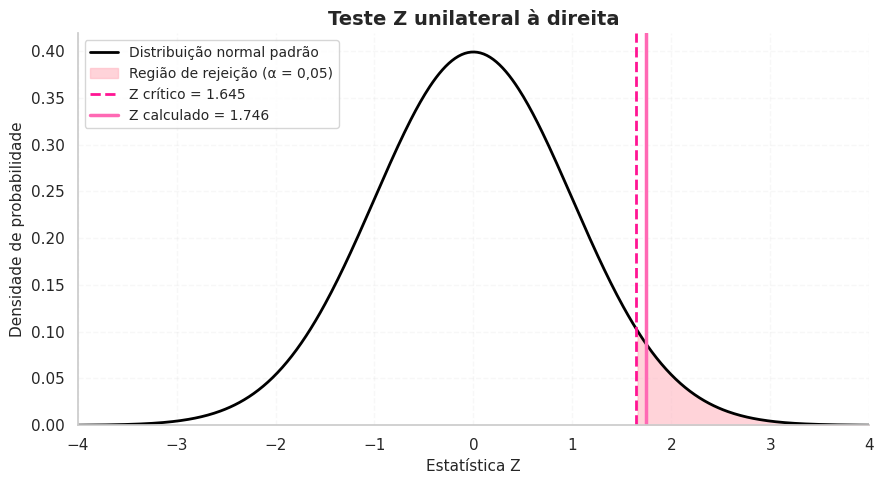

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Distribuição normal padrão
fig, ax = plt.subplots(figsize=(9, 5))

x = np.linspace(-4, 4, 500)
y = stats.norm.pdf(x)

# Curva normal
ax.plot(x, y, color="black", linewidth=2,
        label="Distribuição normal padrão")

# Região de rejeição (5%)
ax.fill_between(
    x, y, where=(x >= z_crit),
    color="lightpink", alpha=0.6,
    label="Região de rejeição (α = 0,05)"
)

# Linha do Z crítico
ax.axvline(
    z_crit, color="deeppink",
    linestyle="--", linewidth=2,
    label=f"Z crítico = {z_crit:.3f}"
)

# Linha do Z calculado
ax.axvline(
    z_calc, color="hotpink",
    linestyle="-", linewidth=2.5,
    label=f"Z calculado = {z_calc:.3f}"
)

# Personalização
ax.set_title("Teste Z unilateral à direita",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Estatística Z", fontsize=11)
ax.set_ylabel("Densidade de probabilidade", fontsize=11)

ax.set_xlim(-4, 4)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.15, linestyle="--")
ax.legend(loc="upper left", fontsize=10)

# Remover bordas superiores e laterais
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



**g) Conclusão:** Os resultados indicam que a proporção de germinação das sementes da espécie nativa (78%) foi estatisticamente superior ao valor de referência de 70%, considerando o nível de significância de 5% (p = 0,0404). Dessa forma, existem evidências estatísticas suficientes para sustentar a afirmação dos pesquisadores. Ecologicamente, a elevada taxa de germinação observada em condições controladas sugere um potencial favorável para a produção de mudas destinadas à restauração ecológica. Entretanto, é importante considerar que o sucesso da germinação em laboratório não garante o estabelecimento das plântulas em ambientes naturais, uma vez que fatores como disponibilidade hídrica, temperatura, luminosidade e condições do solo podem influenciar a germinação e a sobrevivência das plantas.

# Exercício 3: Teste para uma variância (nitrato em um riacho)

**a) Hipóteses:**

- $H_0: \sigma^2 \le 0{,}25$ (mg/L)²
- $H_1: \sigma^2 > 0{,}25$ (mg/L)²

**b) Teste:** O teste adequado é o **teste qui-quadrado** (χ²) para uma variância, unilateral à direita, pois o objetivo é verificar se a variabilidade da concentração de nitrato na água do riacho é significativamente superior ao valor de referência de 0,25 (mg/L)².

O teste t de Student não é apropriado nesse caso, pois é utilizado para testar hipóteses relacionadas às médias populacionais, enquanto o parâmetro de interesse neste exercício é a variância (σ²).

In [12]:

from scipy import stats

# Dados do exercício
alfa = 0.05
n3 = 12
s2 = 0.40
sigma2_0 = 0.25

# c) Estatística qui-quadrado
gl3 = n3 - 1
chi2_calc = gl3 * s2 / sigma2_0

print(f"Qui-quadrado calculado = {chi2_calc:.4f}")

# d) Graus de liberdade
print(f"Graus de liberdade = {gl3}")

# e) Valor crítico unilateral à direita
chi2_crit = stats.chi2.ppf(1 - alfa, gl3)

print(f"Qui-quadrado crítico = {chi2_crit:.4f}")

# f) Decisão estatística
if chi2_calc > chi2_crit:
    print("Decisão: Rejeita H0")
else:
    print("Decisão: Não rejeita H0")


Qui-quadrado calculado = 17.6000
Graus de liberdade = 11
Qui-quadrado crítico = 19.6751
Decisão: Não rejeita H0


**c)** $\chi^2 = \dfrac{(n-1)s^2}{\sigma_0^2} = \dfrac{11 \cdot 0{,}40}{0{,}25} =$ **17,6**

**d)** Graus de liberdade: $n - 1 = 12 - 1 =$ **11**.

**e)** $\chi^2_{crit}$ (5%, 11 gl, cauda direita) = **19,675**.

**f)** Como $17{,}6 < 19{,}675$, **não rejeitamos $H_0$** (p-valor ≈ 0,091).

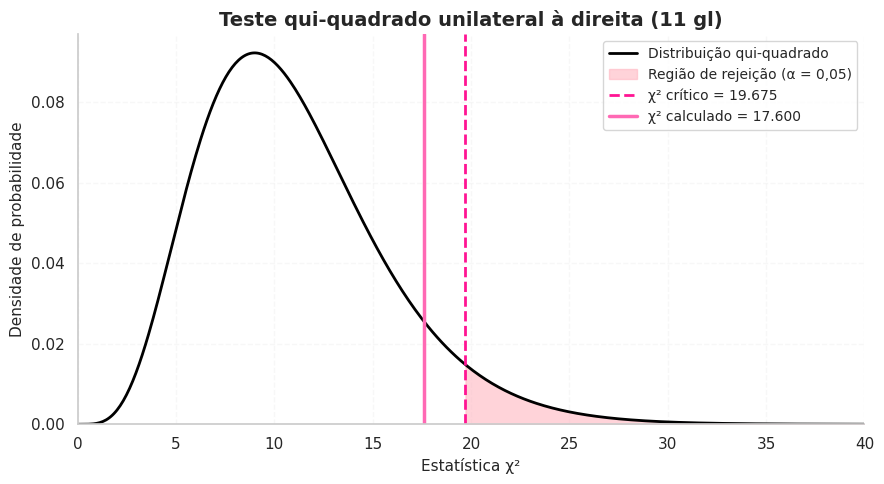

In [14]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Distribuição qui-quadrado
fig, ax = plt.subplots(figsize=(9, 5))

x = np.linspace(0, 40, 500)
y = stats.chi2.pdf(x, gl3)

# Curva da distribuição
ax.plot(x, y, color="black", linewidth=2,
        label="Distribuição qui-quadrado")

# Região de rejeição (5%)
ax.fill_between(
    x, y, where=(x >= chi2_crit),
    color="lightpink", alpha=0.6,
    label="Região de rejeição (α = 0,05)"
)

# Linha do qui-quadrado crítico
ax.axvline(
    chi2_crit, color="deeppink",
    linestyle="--", linewidth=2,
    label=f"χ² crítico = {chi2_crit:.3f}"
)

# Linha do qui-quadrado calculado
ax.axvline(
    chi2_calc, color="hotpink",
    linestyle="-", linewidth=2.5,
    label=f"χ² calculado = {chi2_calc:.3f}"
)

# Personalização
ax.set_title(
    f"Teste qui-quadrado unilateral à direita ({gl3} gl)",
    fontsize=14, fontweight="bold"
)
ax.set_xlabel("Estatística χ²", fontsize=11)
ax.set_ylabel("Densidade de probabilidade", fontsize=11)

ax.set_xlim(0, 40)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.15, linestyle="--")
ax.legend(loc="upper right", fontsize=10)

# Remover bordas
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


**g) Interpretação:** Os resultados indicam que, embora a variância amostral da concentração de nitrato na água do riacho (0,40 (mg/L)²) seja superior ao valor de referência (0,25 (mg/L)²), essa diferença não foi estatisticamente significativa ao nível de 5%. Portanto, não existem evidências suficientes para afirmar que a variabilidade da concentração de nitrato no riacho seja maior que a esperada. Do ponto de vista ecológico, essa variabilidade pode estar associada a fatores ambientais, como escoamento superficial, precipitação e aporte de nutrientes provenientes de atividades agrícolas. Entretanto, seriam necessárias novas amostragens para avaliar melhor a variação espacial e temporal da concentração de nitrato e suas possíveis implicações para a qualidade da água e o funcionamento do ecossistema aquático.

